In [2]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

In [5]:
import os

print("Jupyter is running from:")
print(os.getcwd())

print("\nFiles/folders here:")
print(os.listdir())

print("\nDoes the data file exist?")
print(os.path.exists('../data/world_happiness_2023.csv'))

Jupyter is running from:
C:\Users\asus\dataviz-exercises-maryammoghaddasbayat\week01

Files/folders here:
['.ipynb_checkpoints', 'data', 'lecture02_exercise.ipynb']

Does the data file exist?
False


In [6]:
df = pd.read_csv('data/world_happiness_2023.csv')

In [7]:
df = pd.read_csv('data/world_happiness_2023.csv')

df.columns = [
    'Country',
    'Region',
    'Happiness_Score',
    'GDP',
    'Social_Support',
    'Life_Expectancy',
    'Freedom',
    'Generosity',
    'Corruption'
]

print(f"Dataset: {len(df)} countries, {len(df.columns)} columns")
print(df.head())

Dataset: 63 countries, 9 columns
       Country                        Region  Happiness_Score     GDP  \
0      Finland                Western Europe            7.804  10.775   
1      Denmark                Western Europe            7.586  10.933   
2      Iceland                Western Europe            7.525  10.878   
3       Israel  Middle East and North Africa            7.473  10.527   
4  Netherlands                Western Europe            7.464  11.015   

   Social_Support  Life_Expectancy  Freedom  Generosity  Corruption  
0           0.954             71.9    0.949       0.142       0.179  
1           0.954             72.7    0.931       0.168       0.234  
2           0.983             72.5    0.961       0.260       0.150  
3           0.916             72.4    0.903       0.149       0.826  
4           0.939             72.4    0.879       0.240       0.296  


In [8]:
print("Regions in dataset:")
print(df['Region'].value_counts())

print("\nScore range:")
print(df['Happiness_Score'].min(), "–", df['Happiness_Score'].max())

print("\nBottom 10 countries:")
print(
    df.nsmallest(10, 'Happiness_Score')
      [['Country', 'Region', 'Happiness_Score']]
)

Regions in dataset:
Region
Western Europe                  15
Latin America and Caribbean     13
Central and Eastern Europe       7
Sub-Saharan Africa               7
Middle East and North Africa     6
North America and ANZ            4
Southeast Asia                   4
South Asia                       4
East Asia                        3
Name: count, dtype: int64

Score range:
1.859 – 7.804

Bottom 10 countries:
        Country                        Region  Happiness_Score
60  Afghanistan                    South Asia            1.859
61      Lebanon  Middle East and North Africa            2.392
62     Zimbabwe            Sub-Saharan Africa            2.995
52     Ethiopia            Sub-Saharan Africa            3.564
53     Tanzania            Sub-Saharan Africa            3.698
48   Bangladesh                    South Asia            3.892
47        India                    South Asia            4.036
50        Kenya            Sub-Saharan Africa            4.112
54       Uganda

In [9]:
region_avg = (
    df.groupby('Region')['Happiness_Score']
      .mean()
      .reset_index()
      .sort_values('Happiness_Score')
)

print(region_avg)

                         Region  Happiness_Score
5                    South Asia         3.618250
7            Sub-Saharan Africa         4.064714
3  Middle East and North Africa         4.943333
6                Southeast Asia         5.695250
2   Latin America and Caribbean         5.699000
1                     East Asia         5.966000
0    Central and Eastern Europe         6.338143
4         North America and ANZ         7.018250
8                Western Europe         7.085533


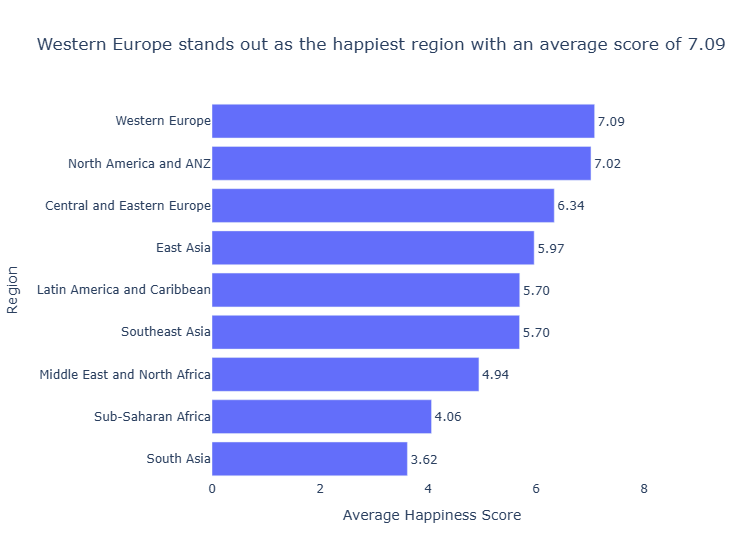

In [10]:
highest_region = region_avg.iloc[-1]['Region']
highest_score = region_avg.iloc[-1]['Happiness_Score']

fig1 = px.bar(
    region_avg,
    x='Happiness_Score',
    y='Region',
    orientation='h',
    text='Happiness_Score',
    title=(
        f"{highest_region} stands out as the happiest region "
        f"with an average score of {highest_score:.2f}"
    )
)

fig1.update_traces(
    texttemplate='%{text:.2f}',
    textposition='outside'
)

fig1.update_layout(
    xaxis_title='Average Happiness Score',
    yaxis_title='Region',
    xaxis=dict(
        range=[0, region_avg['Happiness_Score'].max() * 1.15],
        zeroline=True,
        zerolinewidth=2
    ),
    plot_bgcolor='white',
    paper_bgcolor='white',
    height=550,
    margin=dict(l=180, r=80, t=100, b=70)
)

fig1.show()

In [11]:
top8 = df.nlargest(8, 'Happiness_Score').copy()
top8['Group'] = 'Top 8'

bottom8 = df.nsmallest(8, 'Happiness_Score').copy()
bottom8['Group'] = 'Bottom 8'

combined = pd.concat([bottom8, top8]).sort_values('Happiness_Score')

global_avg = df['Happiness_Score'].mean()

print(f"Global average: {global_avg:.2f}")
print(combined[['Country', 'Happiness_Score', 'Group']])

Global average: 5.81
        Country  Happiness_Score     Group
60  Afghanistan            1.859  Bottom 8
61      Lebanon            2.392  Bottom 8
62     Zimbabwe            2.995  Bottom 8
52     Ethiopia            3.564  Bottom 8
53     Tanzania            3.698  Bottom 8
48   Bangladesh            3.892  Bottom 8
47        India            4.036  Bottom 8
50        Kenya            4.112  Bottom 8
7   Switzerland            7.240     Top 8
6        Norway            7.315     Top 8
5        Sweden            7.395     Top 8
4   Netherlands            7.464     Top 8
3        Israel            7.473     Top 8
2       Iceland            7.525     Top 8
1       Denmark            7.586     Top 8
0       Finland            7.804     Top 8


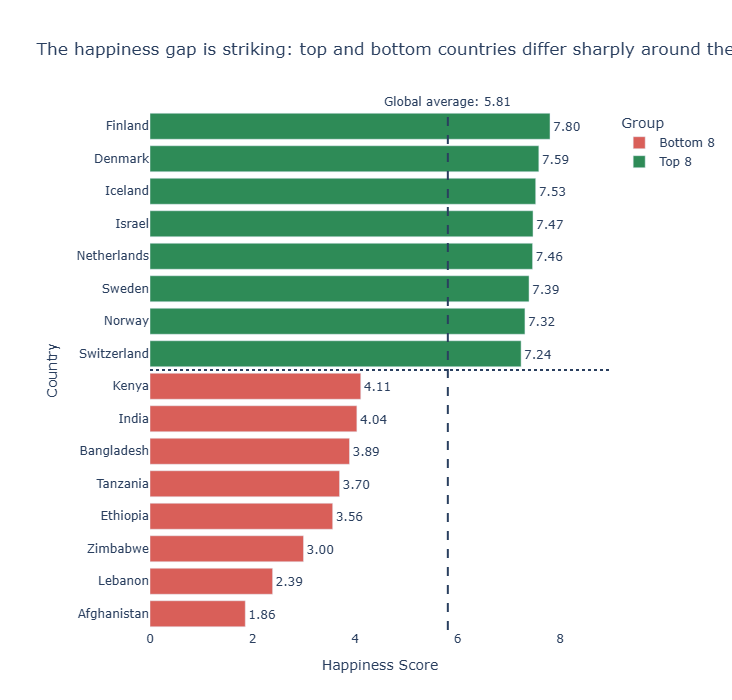

In [12]:
fig2 = px.bar(
    combined,
    x='Happiness_Score',
    y='Country',
    orientation='h',
    color='Group',
    color_discrete_map={
        'Top 8': '#2E8B57',
        'Bottom 8': '#D95F59'
    },
    text='Happiness_Score',
    title=(
        f"The happiness gap is striking: "
        f"top and bottom countries differ sharply "
        f"around the global average of {global_avg:.2f}"
    )
)

fig2.update_traces(
    texttemplate='%{text:.2f}',
    textposition='outside'
)

fig2.add_vline(
    x=global_avg,
    line_dash='dash',
    line_width=2,
    annotation_text=f'Global average: {global_avg:.2f}',
    annotation_position='top'
)

fig2.add_shape(
    type='line',
    x0=0,
    x1=1,
    xref='paper',
    y0=0.5,
    y1=0.5,
    yref='paper',
    line_width=2,
    line_dash='dot'
)

fig2.update_layout(
    xaxis_title='Happiness Score',
    yaxis_title='Country',
    xaxis=dict(
        range=[0, combined['Happiness_Score'].max() * 1.15],
        zeroline=True,
        zerolinewidth=2
    ),
    plot_bgcolor='white',
    paper_bgcolor='white',
    height=700,
    margin=dict(l=150, r=100, t=110, b=70),
    legend_title='Group'
)

fig2.show()